# Hypothesis Test 2: Old vs New Home Size

<div dir="rtl">

«قدیما خونه‌ها دلبازتر بود!» برای بررسی این جمله، میانگین متراژ خانه‌های قدیمی‌ساخت (ساخت قبل از ۱۳۹۶) با خانه‌های جدیدساخت مقایسه می‌شود.

متراژ همان زیربنا (`building_size`) است، چون آپارتمان‌ها متراژ زمین ندارند. سطح معناداری α برابر ۰.۰۵ است.

</div>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

In [2]:
cols = ['cat3_slug', 'construction_year', 'building_size', 'is_residential_unit', 'is_wanted_ad']
df = pd.read_parquet('divar_clean.parquet', columns=cols)

# apartments, houses and villas; a wanted ad is not a real home
homes = df[df['is_residential_unit'] & ~df['is_wanted_ad']]
homes[['construction_year', 'building_size']].isna().sum()

construction_year      31
building_size        3362
dtype: int64

In [3]:
homes = homes.dropna(subset=['construction_year', 'building_size']).copy()
homes['age'] = np.where(homes['construction_year'] < 1396, 'old', 'new')
homes['age'].value_counts()

age
old    347495
new    343524
Name: count, dtype: int64

In [4]:
homes.groupby('age')['building_size'].describe().round(1)

,count,mean,std,min,25%,50%,75%,max
age,,,,,,,,
new,343524.0,131.1,149.5,10.0,85.0,110.0,145.0,9888.0
old,347495.0,110.5,137.0,10.0,70.0,88.0,120.0,9680.0


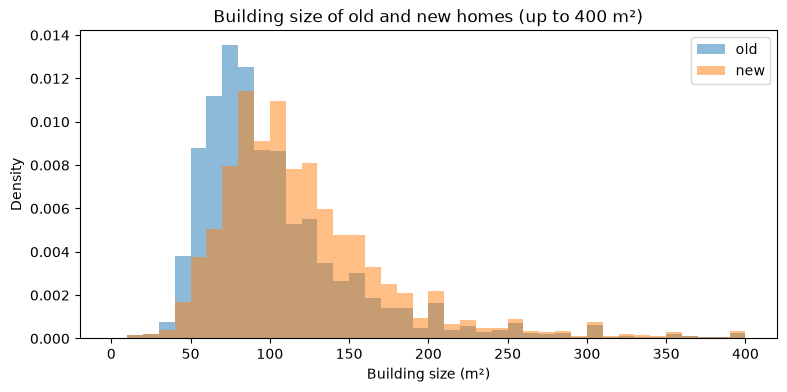

In [5]:
plt.figure(figsize=(9, 4))
bins = np.arange(0, 410, 10)
for age in ['old', 'new']:
    plt.hist(homes.loc[homes['age'] == age, 'building_size'], bins=bins, density=True, alpha=0.5, label=age)
plt.xlabel('Building size (m²)')
plt.ylabel('Density')
plt.title('Building size of old and new homes (up to 400 m²)')
plt.legend()
plt.show()

<div dir="rtl">

خانه‌های جدید در هر سه چارک بزرگ‌ترند (median ۱۱۰ در برابر ۸۸ متر)، پس داده از همین‌جا خلاف فرضیه را نشان می‌دهد. توزیع هر دو گروه right-skewed است و دُمش تا نزدیک ۱۰,۰۰۰ متر می‌رود.

</div>

## Test

<div dir="rtl">

فرضیه جهت دارد، پس آزمون یک‌طرفه است:

</div>

$$H_0: \mu_{old} \le \mu_{new} \qquad H_1: \mu_{old} > \mu_{new}$$

<div dir="rtl">

اول نرمال بودن داده با Shapiro-Wilk بررسی می‌شود. این آزمون برای بیش از ۵,۰۰۰ داده دقیق نیست، پس روی یک نمونه‌ی ۵,۰۰۰ تایی از هر گروه اجرا می‌شود.

</div>

In [6]:
for age in ['old', 'new']:
    sample = homes.loc[homes['age'] == age, 'building_size'].sample(5000, random_state=0)
    w, p = stats.shapiro(sample)
    print(age, round(w, 3), p)

old 0.15 4.7881406021646853e-92
new 0.222 5.289766436815825e-90


<div dir="rtl">

داده نرمال نیست. ولی t-test فقط نرمال بودن میانگین نمونه را لازم دارد، که با بیش از ۳۰۰ هزار آگهی در هر گروه طبق CLT برقرار است. از Welch's t-test استفاده می‌شود که برابری واریانس دو گروه را فرض نمی‌کند، و کنارش Mann-Whitney U که به نرمال بودن نیازی ندارد.

</div>

In [7]:
def compare(data):
    old = data.loc[data['age'] == 'old', 'building_size']
    new = data.loc[data['age'] == 'new', 'building_size']
    diff = old.mean() - new.mean()
    # 95% confidence interval for the difference in means
    se = np.sqrt(old.var() / len(old) + new.var() / len(new))
    return pd.Series({
        'mean_old': old.mean(), 'mean_new': new.mean(),
        'diff': diff, 'ci_low': diff - 1.96 * se, 'ci_high': diff + 1.96 * se,
        'median_old': old.median(), 'median_new': new.median(),
        'p_ttest': stats.ttest_ind(old, new, equal_var=False, alternative='greater').pvalue,
        'p_mannwhitney': stats.mannwhitneyu(old, new, alternative='greater').pvalue})

compare(homes).round(2)

mean_old         110.51
mean_new         131.07
diff             -20.57
ci_low           -21.24
ci_high          -19.89
median_old        88.00
median_new       110.00
p_ttest            1.00
p_mannwhitney      1.00
dtype: float64

<div dir="rtl">

در هر دو آزمون p-value برابر ۱ است، پس $H_0$ رد نمی‌شود. جهت اختلاف هم برعکس فرضیه است: خانه‌های قدیمی‌ساخت به‌طور میانگین حدود ۲۱ متر کوچک‌ترند و کل بازه‌ی اطمینان ۹۵ درصدی این اختلاف زیر صفر است.

</div>

## A Closer Look

<div dir="rtl">

آپارتمان و خانه/ویلا اندازه‌های خیلی متفاوتی دارند، پس همان آزمون برای هر کدام جدا تکرار می‌شود.

</div>

In [8]:
homes['kind'] = np.where(homes['cat3_slug'].str.startswith('apartment'), 'apartment', 'house_villa')
pd.DataFrame({kind: compare(group) for kind, group in homes.groupby('kind')}).T.round(2)

,mean_old,mean_new,diff,ci_low,ci_high,median_old,median_new,p_ttest,p_mannwhitney
apartment,92.57,117.45,-24.88,-25.40,-24.35,82.0,105.0,1.0,1.0
house_villa,156.87,172.67,-15.80,-17.87,-13.73,120.0,120.0,1.0,1.0


<div dir="rtl">

نتیجه در هر دو همان است. در آپارتمان‌ها اختلاف بیشتر است (حدود ۲۵ متر). در خانه و ویلا میانگین قدیمی‌ها ۱۶ متر پایین‌تر است، ولی median دو گروه یکی است (۱۲۰ متر).

مرز ۱۳۹۶ فقط هفت سال قبل از این آگهی‌هاست (۱۴۰۳)، در حالی که «قدیما» معمولاً یعنی چند دهه پیش. برای همین میانگین متراژ برای هر سال ساخت رسم می‌شود و بعد در سه دوره خلاصه می‌شود.

</div>

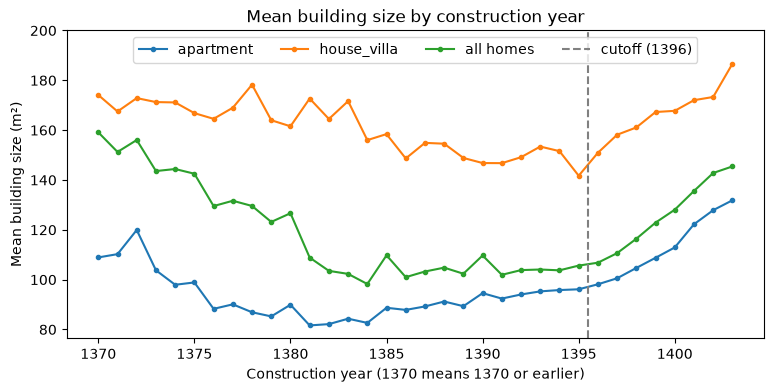

In [9]:
by_year = homes.groupby(['construction_year', 'kind'])['building_size'].mean().unstack()
by_year['all homes'] = homes.groupby('construction_year')['building_size'].mean()
by_year.plot(marker='.', figsize=(9, 4))
plt.axvline(1395.5, color='grey', linestyle='--', label='cutoff (1396)')
plt.xlabel('Construction year (1370 means 1370 or earlier)')
plt.ylabel('Mean building size (m²)')
plt.title('Mean building size by construction year')
plt.ylim(top=200)
plt.legend(loc='upper center', ncol=4)
plt.show()

In [10]:
period = pd.cut(homes['construction_year'], [0, 1379, 1395, 1403],
                labels=['before 1380', '1380 to 1395', '1396 on'])
table = homes.groupby([period, 'kind'], observed=True)['building_size'].mean().unstack()
table['all homes'] = homes.groupby(period, observed=True)['building_size'].mean()
table['house_villa share'] = (homes['kind'] == 'house_villa').groupby(period, observed=True).mean()
table.round(2)

kind,apartment,house_villa,all homes,house_villa share
construction_year,,,,
before 1380,99.96,171.16,147.52,0.67
1380 to 1395,92.22,152.49,106.49,0.24
1396 on,117.45,172.67,131.07,0.25


<div dir="rtl">

منحنی U شکل است: متراژ از ساخت‌های دهه‌ی ۷۰ تا اوایل دهه‌ی ۸۰ پایین می‌آید و از حدود ۱۳۹۶ دوباره سال به سال بالا می‌رود، هم در آپارتمان و هم در خانه و ویلا.

خانه‌های ساخت قبل از ۱۳۸۰ به‌طور میانگین واقعاً بزرگ‌ترند (۱۴۸ در برابر ۱۳۱ متر)، ولی به این دلیل که ۶۷ درصدشان خانه و ویلا هستند؛ این سهم در خانه‌های جدید ۲۵ درصد است. نوع به نوع، آپارتمان‌های آن دوره از آپارتمان‌های جدید کوچک‌ترند (۱۰۰ در برابر ۱۱۷ متر) و خانه‌ها و ویلاها تقریباً هم‌اندازه‌اند.

پس این حس احتمالاً از اینجا می‌آید که قبلاً خانه‌ی ویلایی رایج‌تر بود، نه از کوچک‌تر شدن خود واحدها.

</div>

## Conclusion

<div dir="rtl">

با تعریف صورت پروژه (ساخت قبل از ۱۳۹۶) داده از فرضیه پشتیبانی نمی‌کند: خانه‌های جدیدساخت به‌طور میانگین حدود ۲۱ متر بزرگ‌ترند، و این هم در آپارتمان دیده می‌شود و هم در خانه و ویلا. فقط خانه‌های ساخت قبل از ۱۳۸۰ میانگین بالاتری دارند، آن هم چون بیشترشان ویلایی‌اند.

یک محدودیت: این داده آگهی‌های سال ۱۴۰۳ است، پس از خانه‌های قدیمی فقط آن‌هایی دیده می‌شوند که هنوز سر پا هستند (survivorship bias). خانه‌های بزرگی که تخریب و آپارتمان شده‌اند در داده نیستند.

</div>